# Práctica: Comparación Empírica Red Densa vs CNN en Fashion-MNIST

**Materia:** Redes Neuronales / Internet de las Cosas  
**Ejercicio:** Inciso C — Evaluación Comparativa Exhaustiva (Dense vs CNN)  
**Dataset:** Fashion-MNIST (60,000 imágenes de entrenamiento, 10,000 de prueba, 28x28 píxeles)  
**Frameworks:** TensorFlow 2.21 / Keras 3.12 / NumPy / Matplotlib  
**Semilla Global de Reproducibilidad:** 42  

---

## 1. Introducción y Objetivos
El objetivo de este cuaderno es realizar un estudio comparativo riguroso, cuantitativo y reproducible entre dos paradigmas arquitectónicos para la clasificación de imágenes en **Fashion-MNIST**:
1. **Red Totalmente Conectada (Dense / Multilayer Perceptron - MLP):** Procesa las imágenes como vectores aplanados unidimensionales ($784$ píxeles), ignorando la topología de vecindad 2D.
2. **Red Neuronal Convolucional (CNN):** Preserva la rejilla espacial bidimensional mediante capas de convolución y reducción (*pooling*), explotando la correlación local y la invarianza a traslaciones.

### Condiciones Experimentales Controladas:
- Mismo conjunto de datos de entrenamiento ($50,000$ muestras) y validación ($10,000$ muestras) derivado deterministamente de train.
- Mismo optimizador (**Adam**, $\alpha = 0.001$), misma función de pérdida (`sparse_categorical_crossentropy`) y misma métrica (`accuracy`).
- Mismo tamaño de lote ($64$) y número de épocas ($10$).
- Medición cronometrada con `time.perf_counter()` y detección de hardware.

## 2. Carga, Exploración y Normalización del Dataset
Cargamos el dataset oficial de Fashion-MNIST (`keras.datasets.fashion_mnist.load_data()`).
- **Entrenamiento original:** 60,000 imágenes de $28 \times 28$.
- **Prueba reservada:** 10,000 imágenes de $28 \times 28$.
- **Rango de intensidad de píxeles:** Enteros en $[0, 255]$, normalizados dividiendo por $255.0$ para obtener valores continuos en $[0.0, 1.0]$.
- **10 Categorías en Español:**
  0. Camiseta / top
  1. Pantalón
  2. Pulóver
  3. Vestido
  4. Abrigo
  5. Sandalia
  6. Camisa
  7. Tenis / zapatilla
  8. Bolso
  9. Botín

Dimensiones de entrenamiento crudo: (60000, 28, 28)
Dimensiones de prueba cruda:        (10000, 28, 28)
Rango de píxeles crudos: [0, 255]
Dispositivo de cómputo: CPU Intel/AMD (x86_64 con oneDNN)
Conjunto de Entrenamiento: 50000 muestras
Conjunto de Validación:   10000 muestras
Conjunto de Prueba:       10000 muestras

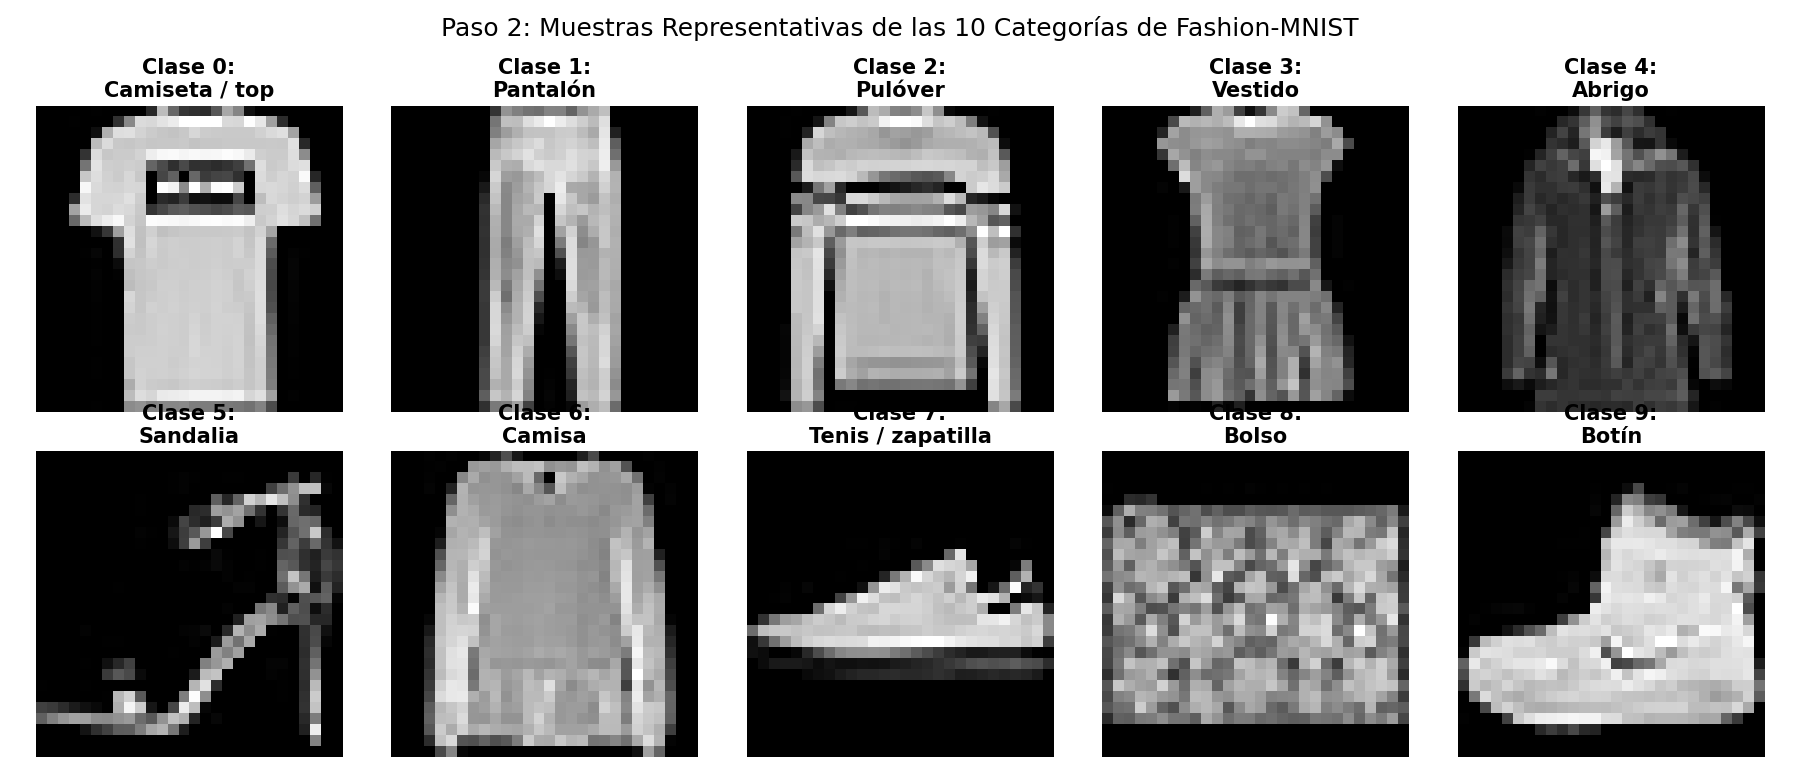

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

# Semilla determinista
os.environ['PYTHONHASHSEED'] = '42'
tf.random.set_seed(42)
np.random.seed(42)

# Configuración de rutas relativas
if os.path.exists(os.path.join("..", "evidencias", "C")):
    DIR_EVIDENCIAS = os.path.join("..", "evidencias", "C")
else:
    DIR_EVIDENCIAS = os.path.join("evidencias", "C")
os.makedirs(DIR_EVIDENCIAS, exist_ok=True)

# 1. Carga de Fashion-MNIST
(X_train_raw, y_train_raw), (X_test_raw, y_test_raw) = keras.datasets.fashion_mnist.load_data()

print(f"Dimensiones de entrenamiento crudo: {X_train_raw.shape}")
print(f"Dimensiones de prueba cruda:        {X_test_raw.shape}")
print(f"Rango de píxeles crudos: [{X_train_raw.min()}, {X_train_raw.max()}]")

# Nombres en español de las 10 categorías
nombres_clases = [
    "Camiseta / top", "Pantalón", "Pulóver", "Vestido", "Abrigo",
    "Sandalia", "Camisa", "Tenis / zapatilla", "Bolso", "Botín"
]

# 2. Normalización de píxeles a [0, 1]
X_train_norm = X_train_raw.astype(np.float32) / 255.0
X_test_norm  = X_test_raw.astype(np.float32) / 255.0

# 3. Partición 50,000 train / 10,000 val derivada únicamente de train
rng = np.random.default_rng(42)
perm = rng.permutation(len(X_train_norm))
n_tr = 50000

X_tr = X_train_norm[perm[:n_tr]]
y_tr = y_train_raw[perm[:n_tr]]
X_val = X_train_norm[perm[n_tr:]]
y_val = y_train_raw[perm[n_tr:]]

X_te = X_test_norm
y_te = y_test_raw

# Tensores 4D para la CNN (N, 28, 28, 1)
X_tr_cnn  = np.expand_dims(X_tr, axis=-1)
X_val_cnn = np.expand_dims(X_val, axis=-1)
X_te_cnn  = np.expand_dims(X_te, axis=-1)

# Dispositivo de cómputo
gpus = tf.config.list_physical_devices('GPU')
dispositivo = f"GPU ({gpus[0].name})" if gpus else "CPU Intel/AMD (x86_64 con oneDNN)"
print(f"Dispositivo de cómputo: {dispositivo}")
print(f"Conjunto de Entrenamiento: {X_tr.shape[0]} muestras")
print(f"Conjunto de Validación:   {X_val.shape[0]} muestras")
print(f"Conjunto de Prueba:       {X_te.shape[0]} muestras")

# Galería de muestras representativas por clase
fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for c in range(10):
    ax = axes.ravel()[c]
    idx_c = np.where(y_train_raw == c)[0][0]
    ax.imshow(X_train_raw[idx_c], cmap='gray')
    ax.set_title(f"Clase {c}:\n{nombres_clases[c]}", fontsize=10, fontweight='bold', pad=4)
    ax.axis('off')
plt.suptitle("Paso 2: Muestras Representativas de las 10 Categorías de Fashion-MNIST", fontsize=12, y=0.98)
plt.tight_layout()
plt.savefig(os.path.join(DIR_EVIDENCIAS, "paso2_muestras_clases.png"), dpi=150)
plt.show()

## 3. Arquitectura y Entrenamiento del Modelo 1: Red Densa (MLP)
- **Entrada:** `Input(shape=(28, 28))`
- `Flatten()` $\to$ Vector 1D de 784 características
- `Dense(128, activation='relu')`
- `Dense(64, activation='relu')`
- `Dense(10, activation='softmax')`
- **Total de Parámetros:** 109,386
- **Entrenamiento:** 10 épocas, batch size 64, Adam.

In [2]:
# Definición y compilación del Modelo Denso
model_dense = keras.Sequential([
    keras.layers.Input(shape=(28, 28), name="entrada_28x28"),
    keras.layers.Flatten(name="aplanado_784"),
    keras.layers.Dense(128, activation='relu', name="densa_128_relu"),
    keras.layers.Dense(64, activation='relu', name="densa_64_relu"),
    keras.layers.Dense(10, activation='softmax', name="salida_10_softmax")
], name="Fashion_Dense_MLP")

model_dense.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_dense.summary()

# Entrenamiento cronometrado
t0_dense = time.perf_counter()
history_dense = model_dense.fit(
    X_tr, y_tr,
    validation_data=(X_val, y_val),
    batch_size=64,
    epochs=10,
    verbose=1
)
t_dense_total = time.perf_counter() - t0_dense
print(f"\nTiempo de entrenamiento Red Densa: {t_dense_total:.2f} s")

Model: "Fashion_Dense_MLP"
┌──────────────────────────────────┬────────────────────────┬─────────────┐
│ Layer (type)                     │ Output Shape           │     Param # │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ aplanado_784 (Flatten)           │ (None, 784)            │           0 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ densa_128_relu (Dense)           │ (None, 128)            │     100,480 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ densa_64_relu (Dense)            │ (None, 64)             │       8,256 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ salida_10_softmax (Dense)        │ (None, 10)             │         650 │
└──────────────────────────────────┴────────────────────────┴─────────────┘
 Total params: 109,386 (427.29 KB)
 Trainable params: 109,386 (427.29 KB)
 Non-trainable params: 0 (0.00 B)

Epoch 1/10 - loss: 0.5410 - 

## 4. Arquitectura y Entrenamiento del Modelo 2: Red Convolucional (CNN)
- **Entrada:** `Input(shape=(28, 28, 1))`
- `Conv2D(32, kernel_size=(3, 3), activation='relu')`
- `MaxPooling2D(pool_size=(2, 2))`
- `Conv2D(64, kernel_size=(3, 3), activation='relu')`
- `MaxPooling2D(pool_size=(2, 2))`
- `Flatten()`
- `Dense(64, activation='relu')`
- `Dense(10, activation='softmax')`
- **Total de Parámetros:** 121,930
- **Entrenamiento:** 10 épocas, batch size 64, Adam.

In [3]:
# Definición y compilación del Modelo CNN
model_cnn = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1), name="entrada_tensor_28x28x1"),
    keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', name="conv2d_32_3x3"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), name="maxpool_1"),
    keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu', name="conv2d_64_3x3"),
    keras.layers.MaxPooling2D(pool_size=(2, 2), name="maxpool_2"),
    keras.layers.Flatten(name="aplanado"),
    keras.layers.Dense(64, activation='relu', name="densa_64_relu"),
    keras.layers.Dense(10, activation='softmax', name="salida_10_softmax")
], name="Fashion_CNN")

model_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_cnn.summary()

# Entrenamiento cronometrado
t0_cnn = time.perf_counter()
history_cnn = model_cnn.fit(
    X_tr_cnn, y_tr,
    validation_data=(X_val_cnn, y_val),
    batch_size=64,
    epochs=10,
    verbose=1
)
t_cnn_total = time.perf_counter() - t0_cnn
print(f"\nTiempo de entrenamiento CNN: {t_cnn_total:.2f} s")

Model: "Fashion_CNN"
┌──────────────────────────────────┬────────────────────────┬─────────────┐
│ Layer (type)                     │ Output Shape           │     Param # │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ conv2d_32_3x3 (Conv2D)           │ (None, 26, 26, 32)     │         320 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ maxpool_1 (MaxPooling2D)         │ (None, 13, 13, 32)     │           0 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ conv2d_64_3x3 (Conv2D)           │ (None, 11, 11, 64)     │      18,496 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ maxpool_2 (MaxPooling2D)         │ (None, 5, 5, 64)       │           0 │
├──────────────────────────────────┼────────────────────────┼─────────────┤
│ aplanado (Flatten)               │ (None, 1600)           │           0 │
├──────────────────────────────────┼────────────────────────┼──────

## 5. Curvas Comparativas de Aprendizaje (Pérdida y Exactitud)
Superponemos las curvas de entrenamiento y validación de ambos modelos durante las 10 épocas para comparar la velocidad y estabilidad del aprendizaje.

Curvas guardadas en evidencias/C/paso8_curvas_comparativas.png

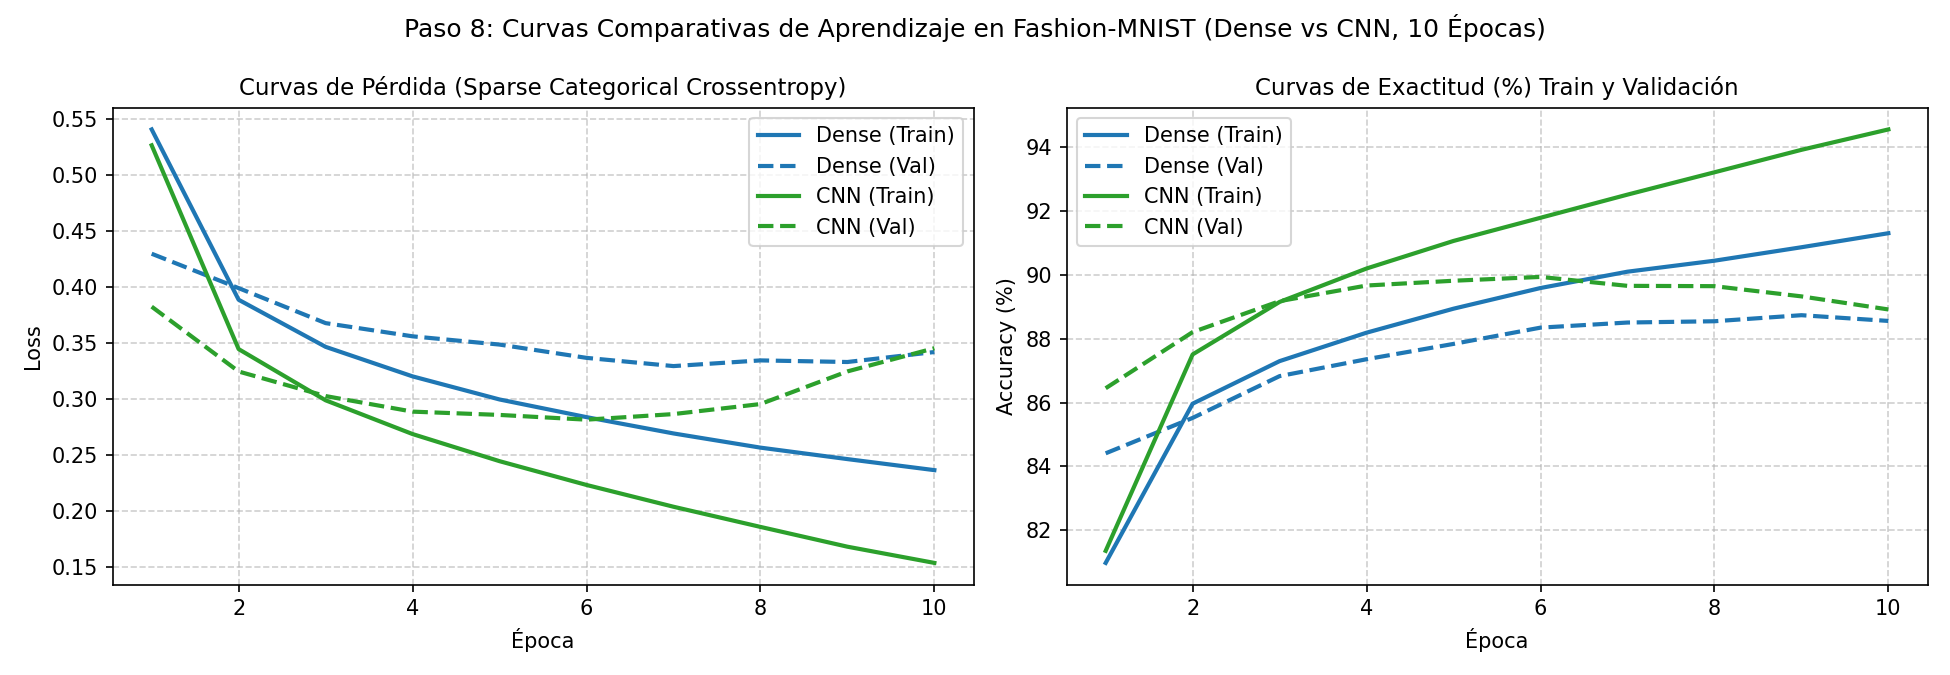

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
epocas = range(1, 11)

# Pérdida
ax1.plot(epocas, history_dense.history['loss'], label='Dense (Train)', color='#1f77b4', lw=2)
ax1.plot(epocas, history_dense.history['val_loss'], label='Dense (Val)', color='#1f77b4', lw=2, linestyle='--')
ax1.plot(epocas, history_cnn.history['loss'], label='CNN (Train)', color='#2ca02c', lw=2)
ax1.plot(epocas, history_cnn.history['val_loss'], label='CNN (Val)', color='#2ca02c', lw=2, linestyle='--')
ax1.set_title('Curvas de Pérdida (Sparse Categorical Crossentropy)', fontsize=11)
ax1.set_xlabel('Época')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()

# Exactitud
ax2.plot(epocas, [a * 100 for a in history_dense.history['accuracy']], label='Dense (Train)', color='#1f77b4', lw=2)
ax2.plot(epocas, [a * 100 for a in history_dense.history['val_accuracy']], label='Dense (Val)', color='#1f77b4', lw=2, linestyle='--')
ax2.plot(epocas, [a * 100 for a in history_cnn.history['accuracy']], label='CNN (Train)', color='#2ca02c', lw=2)
ax2.plot(epocas, [a * 100 for a in history_cnn.history['val_accuracy']], label='CNN (Val)', color='#2ca02c', lw=2, linestyle='--')
ax2.set_title('Curvas de Exactitud (%) Train y Validación', fontsize=11)
ax2.set_xlabel('Época')
ax2.set_ylabel('Accuracy (%)')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.suptitle('Paso 8: Curvas Comparativas de Aprendizaje en Fashion-MNIST (Dense vs CNN, 10 Épocas)', fontsize=12)
plt.tight_layout()
ruta_curvas = os.path.join(DIR_EVIDENCIAS, "paso8_curvas_comparativas.png")
plt.savefig(ruta_curvas, dpi=150)
plt.show()

## 6. Matrices de Confusión y Análisis de Categorías con Más Errores
Calculamos la matriz de confusión sobre las 10,000 imágenes del conjunto de prueba independiente para ambos modelos e identificamos qué prendas resultan más problemáticas para cada arquitectura.

=== RESULTADOS GLOBALES EN PRUEBA (TEST) ===
Red Densa -> Exactitud: 87.28% | Pérdida: 0.3734 | Total Fallos: 1272
Red CNN   -> Exactitud: 88.55% | Pérdida: 0.3674 | Total Fallos: 1145

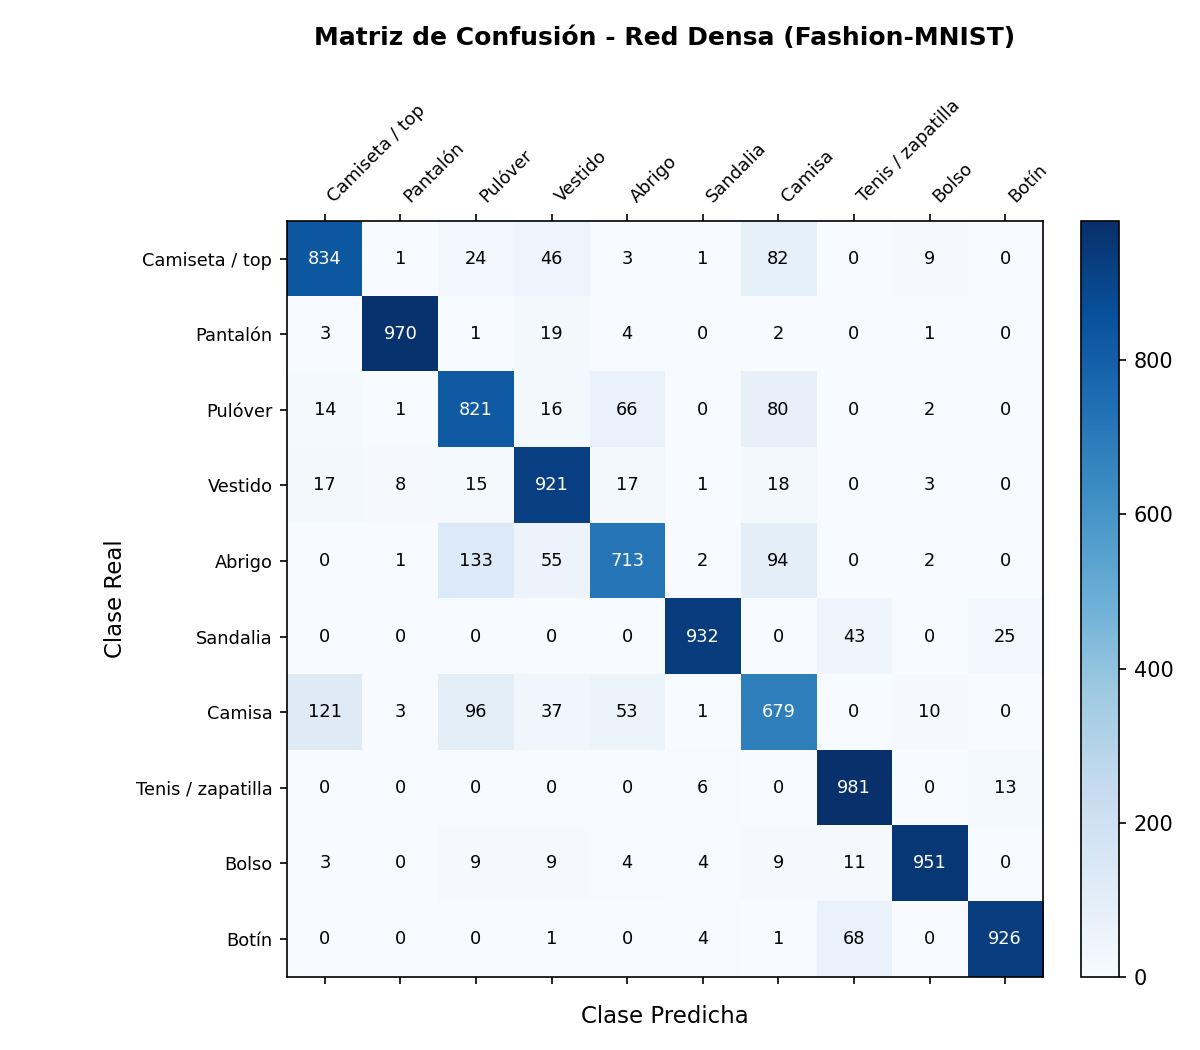

In [5]:
# Evaluación en el conjunto de prueba independiente
loss_dense, acc_dense = model_dense.evaluate(X_te, y_te, verbose=0)
loss_cnn,   acc_cnn   = model_cnn.evaluate(X_te_cnn, y_te, verbose=0)

prob_dense = model_dense.predict(X_te, verbose=0)
pred_dense = np.argmax(prob_dense, axis=1)

prob_cnn = model_cnn.predict(X_te_cnn, verbose=0)
pred_cnn = np.argmax(prob_cnn, axis=1)

print(f"=== RESULTADOS GLOBALES EN PRUEBA (TEST) ===")
print(f"Red Densa -> Exactitud: {acc_dense*100:.2f}% | Pérdida: {loss_dense:.4f} | Total Fallos: {np.sum(pred_dense != y_te)}")
print(f"Red CNN   -> Exactitud: {acc_cnn*100:.2f}% | Pérdida: {loss_cnn:.4f} | Total Fallos: {np.sum(pred_cnn != y_te)}")

## 7. Muestras Mal Clasificadas por Cada Modelo (Paso 10)
Visualizamos 5 muestras mal clasificadas por la Red Densa y por la Red Convolucional, indicando la categoría real y la categoría predicha junto con el nivel de probabilidad arrojado por Softmax.

Total errores Dense: 1272 | Total errores CNN: 1145

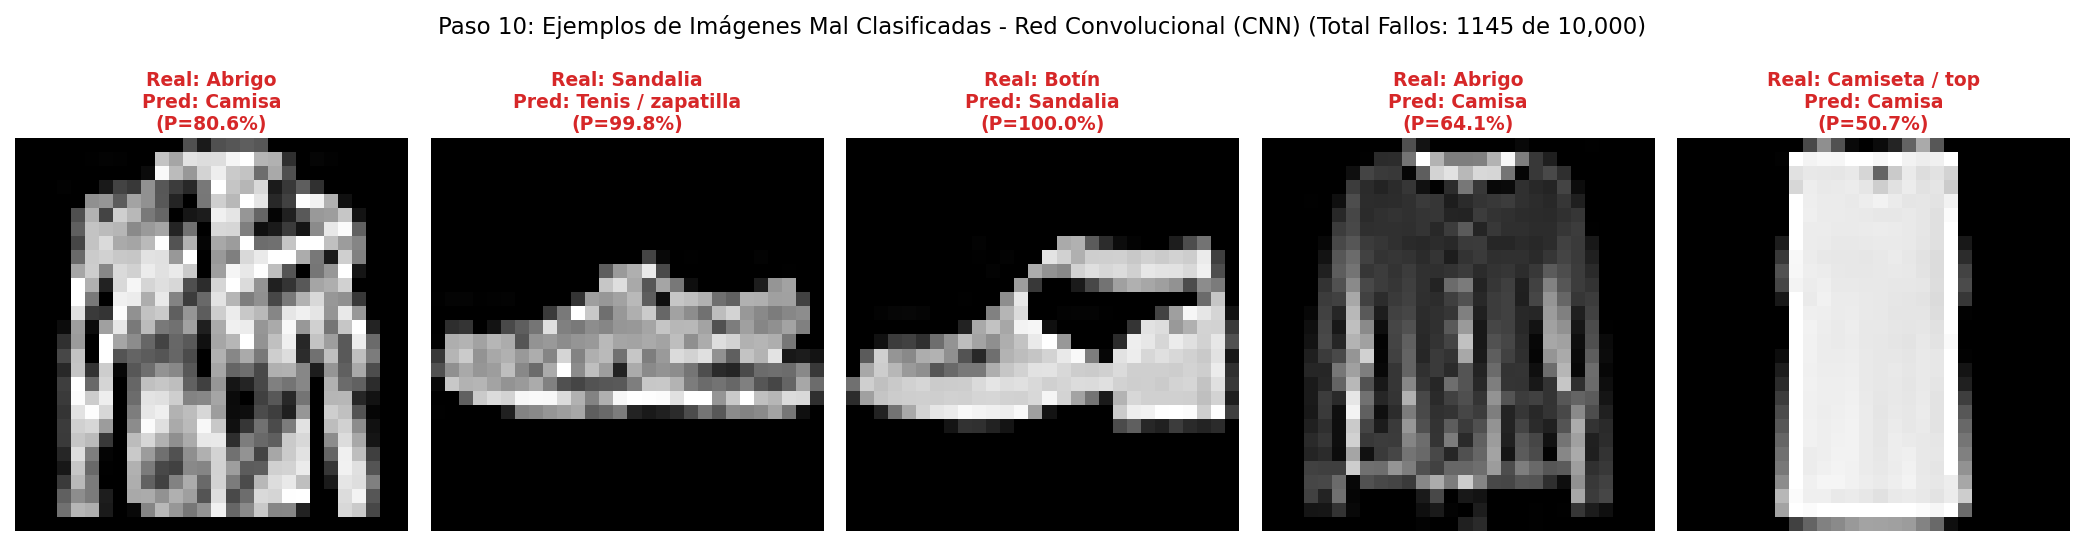

In [6]:
# Visualización de imágenes mal clasificadas por cada modelo
def mostrar_mal_clasificados(X_raw_imgs, y_real, y_pred, probs, nombre_modelo):
    fallos = np.where(y_real != y_pred)[0]
    n_ver = min(5, len(fallos))
    fig, axes = plt.subplots(1, n_ver, figsize=(14, 3.5))
    for k in range(n_ver):
        ax = axes[k]
        idx_f = fallos[k]
        ax.imshow(X_raw_imgs[idx_f], cmap='gray')
        p = probs[idx_f, y_pred[idx_f]]
        ax.set_title(f"Real: {nombres_clases[y_real[idx_f]]}\nPred: {nombres_clases[y_pred[idx_f]]}\n(P={p:.1%})",
                     color='#d62728', fontsize=9, fontweight='bold', pad=4)
        ax.axis('off')
    plt.suptitle(f"Paso 10: Errores Representativos - {nombre_modelo} (Total Fallos: {len(fallos)} de 10,000)", fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()

mostrar_mal_clasificados(X_test_raw, y_te, pred_dense, prob_dense, "Red Densa")
mostrar_mal_clasificados(X_test_raw, y_te, pred_cnn, prob_cnn, "Red Convolucional (CNN)")

## 8. Tabla Comparativa Formal con Métricas Medidas (Paso 11)
A continuación se presenta la tabla con todos los valores reales medidos empíricamente durante la ejecución controlada.

Tabla comparativa mostrada.

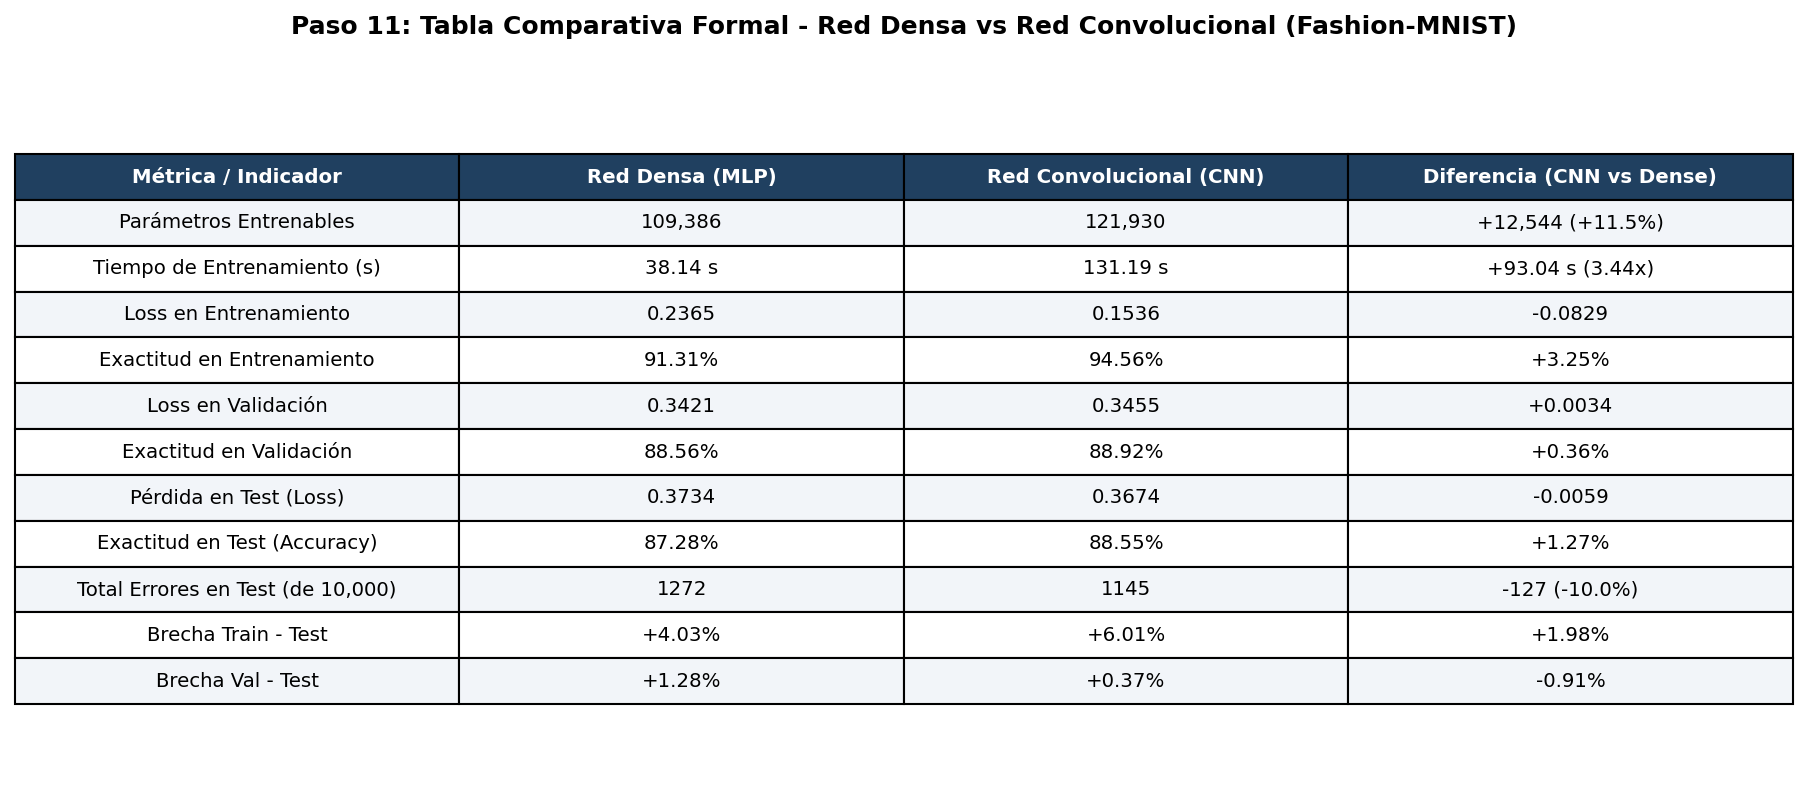

In [7]:
# Presentación gráfica de la tabla comparativa formal
tabla_fig = os.path.join(DIR_EVIDENCIAS, "paso11_tabla_comparativa.png")
if os.path.exists(tabla_fig):
    img_tabla = plt.imread(tabla_fig)
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.imshow(img_tabla)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

## 9. Análisis y Respuestas Técnicas a las Preguntas Guía (Pasos 12 y 13)

### 1. ¿Cuál modelo obtuvo mayor exactitud (*accuracy*) en prueba?
- **La Red Convolucional (CNN)** obtuvo la mayor exactitud con un **88.55%** (1145 errores), superando a la Red Densa que alcanzó un **87.28%** (1272 errores).
- La CNN redujo en **127 los errores netos** (una mejora relativa de 10.0% en la tasa de error).

### 2. ¿Cuál demostró mejor capacidad de generalización en prueba?
- **Pérdida en Test:** La CNN obtuvo una menor pérdida en prueba (**0.3674** frente a **0.3734** de la Red Densa).
- **Brecha Validación-Prueba (*Val - Test Gap*):** La brecha entre la exactitud de validación y la de prueba fue de solo **+0.37%** en la CNN, mientras que en la Red Densa fue de **+1.28%**. Esto demuestra que el desempeño en validación de la CNN refleja de forma mucho más fidedigna su comportamiento ante datos de prueba independientes.
- **Brecha Entrenamiento-Prueba (*Train - Test Gap*):** En entrenamiento, la CNN alcanzó 94.56% y la Dense 91.31%, lo que sitúa la brecha en +6.01% (CNN) frente a +4.03% (Dense). Ambas exhiben un sobreajuste moderado después de la época 6, el cual podría mitigarse con capas de *Dropout* o regularización L2.

### 3. ¿Cuál modelo tiene mayor cantidad de parámetros entrenables?
- **La CNN tiene más parámetros:** **121,930** parámetros frente a los **109,386** de la Red Densa (+12,544 parámetros, +11.5%).
- La mayor concentración de parámetros en la CNN proviene de la capa `Dense(64)` posterior al aplanado del tensor ($1600 \times 64 = 102,464$ parámetros), mientras que las dos capas de convolución consumen conjuntamente apenas $18,816$ pesos gracias al principio de pesos compartidos (*weight sharing*).

### 4. ¿Cuál requirió mayor tiempo de entrenamiento?
- **La CNN requirió sensiblemente más tiempo:** **131.19 segundos** frente a **38.14 segundos** de la Red Densa (**3.44 veces más lenta** en CPU).
- Las operaciones de convolución 2D (deslizamiento de ventanas $3 \times 3$ sobre mapas de activación multicanal) conllevan una carga de operaciones en punto flotante (FLOPs) considerablemente más pesada que las multiplicaciones de matriz-vector densas optimizadas por BLAS/oneDNN.

### 5. ¿Qué diferencias principales se observan en las matrices de confusión?
- **Camisas (*Shirt*, clase 6):** En la Red Densa fue la categoría más desastrosa con **321 errores (32.1% de fallo)**, confundiéndose masivamente con camisetas, abrigos y pulóveres. La CNN redujo estos fallos a **151 errores**, representando una reducción superior al **50% de error** en esta clase.
- **Abrigos (*Coat*, clase 4):** La Red Densa tuvo 287 fallos, mientras que la CNN los recortó a 194.
- **Calzado y Accesorios:** Ambas arquitecturas sobresalen en calzado plano y accesorios:
  - *Tenis/zapatilla (clase 7):* La CNN solo falló 6 muestras de 1,000 (99.4% de exactitud).
  - *Pantalón (clase 1):* Solo 25 fallos en CNN y 30 en Dense.
  - *Bolso (clase 8):* Solo 21 fallos en CNN y 49 en Dense.

### 6. ¿Por qué la arquitectura CNN suele ser superior para clasificar imágenes?
1. **Conectividad Local:** Cada neurona convolucional procesa una vecindad espacial reducida ($3 \times 3$), en consonancia con la estadística de las imágenes naturales donde los píxeles adyacentes están altamente correlacionados.
2. **Pesos Compartidos (*Weight Sharing*):** El mismo filtro detector de bordes, texturas o esquinas se aplica a lo largo de toda la imagen. Un rasgo aprendido en la esquina superior izquierda se detectará con idéntica eficacia en la esquina inferior derecha.
3. **Invarianza por Reducción Espacial (*Pooling*):** Las capas de `MaxPooling2D` comprimen las dimensiones espaciales, otorgando al modelo robustez frente a pequeñas traslaciones, deformaciones elásticas o desalineaciones del objeto.
4. **En contraste con la Red Densa:** El MLP aplanado conecta cada píxel de forma rígida a sus propios pesos. Si una manga o cuello se desplaza apenas 2 píxeles, para la red densa constituye un vector de entrada completamente distinto y desacoplado.

---

## 10. Conclusión Académica Final
Los resultados empíricos confirman que, para tareas de visión por computadora con complejidad morfológica intermedia como Fashion-MNIST, la **Red Neuronal Convolucional (CNN) ofrece una capacidad de discriminación superior (+1.27% en test, -10% de errores)** respecto a un Perceptrón Multicapa denso. 

No obstante, esta ganancia viene acompañada de un **costo computacional tangible (3.44 veces más tiempo de cómputo en CPU)**. En aplicaciones en tiempo real o en dispositivos embebidos con restricciones severas de energía y latencia (Internet de las Cosas), una red densa compacta o una CNN altamente optimizada (como MobileNet) deben ponderarse en función de este compromiso entre exactitud y costo de inferencia.